# Lab 3: Bài Toán Xe Lấy Đà Leo Đồi (Mountain Car) với SARSA & Rời Rạc Hóa Trạng Thái

## 1. Mô tả bài toán (Sutton & Barto, Example 10.1)
Một chiếc xe nằm dưới thung lũng giữa hai ngọn đồi và cần leo lên đỉnh đồi bên phải tại vị trí $x = 0.5$. Tuy nhiên, trọng lực mạnh hơn động cơ của xe nên xe không thể chạy thẳng một mạch lên dốc mà phải **lùi lên ngọn đồi bên trái để lấy đà**, sau đó mới tăng tốc vượt dốc phải:
- **Trạng thái liên tục (Continuous State)**: Vị trí $x \in [-1.2, 0.5]$ và vận tốc $v \in [-0.07, 0.07]$.
- **Hành động (Actions)**: `0 = Đẩy sang trái (-1)`, `1 = Thả trôi (0)`, `2 = Đẩy sang phải (+1)`.
- **Cập nhật vật lý**:
  $$v_{t+1} = \text{clip}(v_t + 0.001(\text{action} - 1) - 0.0025 \cos(3 x_t), -0.07, 0.07)$$
  $$x_{t+1} = \text{clip}(x_t + v_{t+1}, -1.2, 0.5)$$
- **Phần thưởng (Reward)**: $-1$ tại mỗi bước thời gian cho đến khi xe chạm đỉnh đồi ($x \ge 0.5$).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

## 2. Xây dựng môi trường vật lý `MountainCarEnv`

In [2]:
class MountainCarEnv:
    def __init__(self, seed=42):
        self.rng = np.random.default_rng(seed)
        self.min_pos, self.max_pos = -1.2, 0.5
        self.max_vel = 0.07
        self.goal_pos = 0.5
        self.num_actions = 3
        self.reset()

    def reset(self):
        self.pos = self.rng.uniform(-0.6, -0.4)
        self.vel = 0.0
        return (self.pos, self.vel)

    def step(self, action):
        force = action - 1
        self.vel += 0.001 * force - 0.0025 * np.cos(3.0 * self.pos)
        self.vel = np.clip(self.vel, -self.max_vel, self.max_vel)
        self.pos += self.vel
        self.pos = np.clip(self.pos, self.min_pos, self.max_pos)
        if self.pos == self.min_pos and self.vel < 0:
            self.vel = 0.0
        done = bool(self.pos >= self.goal_pos)
        return (self.pos, self.vel), -1.0, done

## 3. Rời rạc hóa trạng thái (State Discretization / Aggregation) & Thuật toán SARSA

In [3]:
def discretize_state(state, pos_bins, vel_bins):
    pos, vel = state
    p_idx = np.clip(int(np.digitize(pos, pos_bins)) - 1, 0, len(pos_bins) - 2)
    v_idx = np.clip(int(np.digitize(vel, vel_bins)) - 1, 0, len(vel_bins) - 2)
    return (p_idx, v_idx)

def epsilon_greedy_policy(Q, state_idx, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(0, 3))
    return int(np.argmax(Q[state_idx]))

def sarsa_mountain_car(env, num_episodes=1000, n_bins=20, alpha=0.15, gamma=0.99, epsilon=0.05, max_steps=500):
    pos_bins = np.linspace(env.min_pos, env.max_pos, n_bins + 1)
    vel_bins = np.linspace(-env.max_vel, env.max_vel, n_bins + 1)
    Q = np.zeros((n_bins, n_bins, env.num_actions))
    steps_per_episode = []

    for ep in range(num_episodes):
        state = env.reset()
        s_idx = discretize_state(state, pos_bins, vel_bins)
        action = epsilon_greedy_policy(Q, s_idx, epsilon, env.rng)
        steps = 0
        for _ in range(max_steps):
            next_state, reward, done = env.step(action)
            next_s_idx = discretize_state(next_state, pos_bins, vel_bins)
            next_action = epsilon_greedy_policy(Q, next_s_idx, epsilon, env.rng)
            td_target = reward if done else reward + gamma * Q[next_s_idx + (next_action,)]
            Q[s_idx + (action,)] += alpha * (td_target - Q[s_idx + (action,)])
            s_idx, action = next_s_idx, next_action
            steps += 1
            if done:
                break
        steps_per_episode.append(steps)

    return Q, pos_bins, vel_bins, steps_per_episode

## 4. Huấn luyện và Biểu diễn Quỹ đạo Xe Lấy Đà Leo Đồi

Số bước trung bình (50 episodes đầu):  500.0 bước
Số bước trung bình (50 episodes cuối): 184.6 bước
Kiểm thử chính sách tối ưu: Xe chạm đỉnh đồi sau 198 bước!


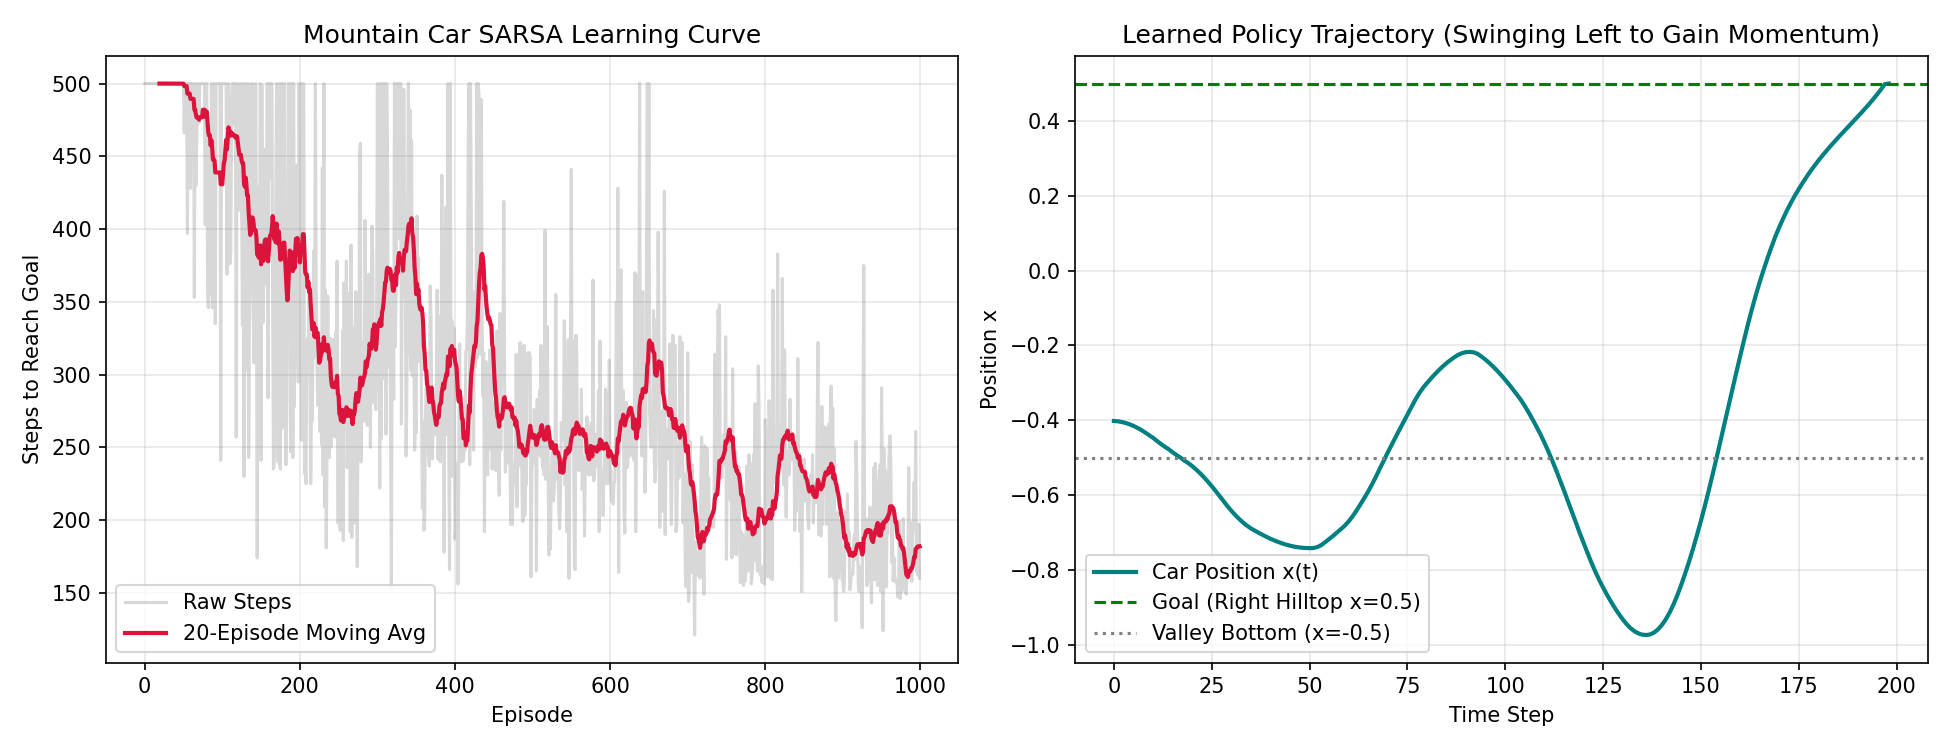

In [4]:
env = MountainCarEnv(seed=42)
Q, pos_bins, vel_bins, steps_history = sarsa_mountain_car(
    env, num_episodes=1000, n_bins=20, alpha=0.15, gamma=0.99, epsilon=0.05
)

print(f"Số bước trung bình (50 episodes đầu):  {np.mean(steps_history[:50]):.1f} bước")
print(f"Số bước trung bình (50 episodes cuối): {np.mean(steps_history[-50:]):.1f} bước")

state = env.reset()
positions = [state[0]]
for _ in range(300):
    s_idx = discretize_state(state, pos_bins, vel_bins)
    action = int(np.argmax(Q[s_idx]))
    state, _, done = env.step(action)
    positions.append(state[0])
    if done:
        break
print(f"Kiểm thử chính sách tối ưu: Xe chạm đỉnh đồi sau {len(positions) - 1} bước!")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
window = 20
smoothed = np.convolve(steps_history, np.ones(window) / window, mode="valid")
axes[0].plot(steps_history, alpha=0.3, color="gray", label="Raw Steps")
axes[0].plot(range(window - 1, len(steps_history)), smoothed, color="crimson", lw=2, label="20-Episode Moving Avg")
axes[0].set_title("Mountain Car SARSA Learning Curve")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Steps to Reach Goal")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(positions, color="teal", lw=2, label="Car Position x(t)")
axes[1].axhline(env.goal_pos, color="green", linestyle="--", label="Goal (Right Hilltop x=0.5)")
axes[1].axhline(-0.5, color="gray", linestyle=":", label="Valley Bottom (x=-0.5)")
axes[1].set_title("Learned Policy Trajectory (Swinging Left to Gain Momentum)")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Position x")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()